# Titanic Survival Prediction — Supervised Machine Learning Classification

**Inovegen AI/ML Internship Program 2026 — Task 2: Classification Model & Evaluation**

- **Dataset:** `Titanic-Dataset.csv` (the classic Kaggle Titanic passenger dataset, 891 rows, 12 columns)
- **Prediction target:** `Survived` (0 = did not survive, 1 = survived)
- **Problem type:** Binary classification (supervised learning)

## 2. Objective

The objective of this notebook is to build a **supervised machine-learning classification model** that predicts whether a Titanic passenger survived, based on passenger characteristics such as class, sex, age, fare, and family size.

This is a **classification problem** (not regression) because the target variable, `Survived`, only takes two discrete values (0 or 1) rather than a continuous number.

The model learns patterns from historical, labeled data (passengers whose survival outcome is already known) and uses those patterns to predict the outcome for passengers it has not seen during training.

**Important:** this model identifies statistical *associations* between passenger characteristics and survival in this historical dataset. It does **not** establish that any feature *caused* survival.

## 3. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (7, 5)
pd.set_option("display.max_columns", None)

## 4. Load the Dataset

**Dataset/source note:** the data is loaded directly from the provided file `Titanic-Dataset.csv` — the classic Kaggle Titanic "train" dataset containing 891 passenger records.

In [2]:
df = pd.read_csv("Titanic-Dataset.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())

Shape: (891, 12)

Columns: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


**What the dataset contains:** one row per passenger, with demographic information (`Sex`, `Age`), travel details (`Pclass`, `Fare`, `Embarked`, `Ticket`, `Cabin`), family relationships aboard (`SibSp`, `Parch`), an identifier (`PassengerId`, `Name`), and the outcome we want to predict (`Survived`).

## 5. Initial Data Inspection

In [5]:
df.shape

(891, 12)

In [6]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [7]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [8]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

**Findings:**
- 891 rows, 12 columns.
- `Age` is missing for 177 passengers (~19.9%).
- `Cabin` is missing for 687 passengers (~77.1%) — too sparse to use reliably as a direct feature.
- `Embarked` is missing for 2 passengers.
- There are no duplicate rows.
- The target `Survived` is a clean binary column (0/1) with no missing values.

## 6. Define Features and Target

The prediction target is `Survived`. We separate it from the rest of the dataset immediately so that it cannot accidentally be used as an input feature (which would cause data leakage — the model "cheating" by seeing the answer).

In [11]:
target = "Survived"

X = df.drop(columns=[target])
y = df[target]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Features shape: (891, 11)
Target shape: (891,)

Target distribution:
Survived
0    549
1    342
Name: count, dtype: int64


## 7. Remove Irrelevant Features

Not every column is useful for a beginner-friendly predictive model. We remove:

- **`PassengerId`** — a unique identifier with no predictive meaning; it exists only to number rows.
- **`Name`** — a mostly unique text field per passenger. Extracting a title (Mr/Mrs/Miss) is possible but adds text-processing complexity beyond what this task needs, so it is excluded to keep the model simple and explainable.
- **`Ticket`** — an inconsistent alphanumeric code with no clear numerical or categorical meaning without heavy text parsing, so it is excluded.
- **`Cabin`** — missing for ~77% of passengers. Rather than inventing cabin values for most of the dataset, we drop the raw column. (Its only reliably usable signal — whether a cabin was recorded at all — is captured separately below as a simple engineered feature.)

We keep `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, and `Embarked`, since these are meaningful, mostly complete passenger characteristics.

In [12]:
# Create a simple engineered feature: whether a cabin was recorded at all
X["Has_Cabin"] = X["Cabin"].notnull().astype(int)

# Drop columns that are not useful predictive features
X = X.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

X.columns.tolist()

['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'Has_Cabin']

## 8. Data Cleaning and Preparation

### Missing values

`Age` (~19.9% missing) and `Embarked` (2 missing) still contain missing values. Rather than dropping these rows (which would discard real passenger data), we handle them using imputation **inside the preprocessing pipeline** built later, so that:

- Numerical missing values (`Age`) are filled with the **median** — robust to outliers such as very old or very young passengers.
- Categorical missing values (`Embarked`) are filled with the **most frequent value (mode)** — a low-risk choice given very few missing values.

Doing this inside a pipeline (rather than manually on the full dataset) ensures the imputation values are learned **only from the training data**, avoiding data leakage from the test set.

In [13]:
X.isnull().sum()

Pclass         0
Sex            0
Age          177
SibSp          0
Parch          0
Fare           0
Embarked       2
Has_Cabin      0
dtype: int64

## 9. Categorical Variables

`Sex` and `Embarked` are categorical (text) columns. Machine-learning models like Logistic Regression and Random Forest work with numbers, not text, so categorical values must be converted into a numeric form.

We use **One-Hot Encoding** (`OneHotEncoder`), which creates a separate 0/1 column for each category (e.g., `Sex_male`, `Embarked_Q`, `Embarked_S`). This avoids implying a false numeric order between categories (e.g., it would be wrong to encode "S", "C", "Q" as 1, 2, 3, since ports have no natural ranking).

In [14]:
categorical_features = ["Sex", "Embarked"]
X[categorical_features].nunique()

Sex         2
Embarked    3
dtype: int64

## 10. Numerical Features

The numerical features are `Pclass`, `Age`, `SibSp`, `Parch`, and `Fare`.

We apply **`StandardScaler`** (rescales each feature to mean 0, standard deviation 1) because Logistic Regression is sensitive to the scale of input features — a feature like `Fare` (ranging up to ~£512) could otherwise dominate a feature like `Pclass` (ranging 1–3) purely due to scale, not real importance.

Note: scaling is **not required for every model** — tree-based models like Random Forest are unaffected by feature scale, since they split on threshold values rather than distances. We still apply the same scaled pipeline to both models here for simplicity and consistency, since scaling does not harm Random Forest's performance.

In [15]:
numerical_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
X[numerical_features].describe()

,Pclass,Age,SibSp,Parch,Fare
count,891.000000,714.000000,891.000000,891.000000,891.000000
mean,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.420000,0.000000,0.000000,0.000000
25%,2.000000,20.125000,0.000000,0.000000,7.910400
50%,3.000000,28.000000,0.000000,0.000000,14.454200
75%,3.000000,38.000000,1.000000,0.000000,31.000000
max,3.000000,80.000000,8.000000,6.000000,512.329200


## 11. Train/Test Split

We split the data into a **training set** (used to fit the model) and a **testing set** (used only to evaluate the model afterward, simulating unseen passengers).

- `test_size=0.2` — 20% of the data is held out for testing.
- `random_state=42` — makes the split reproducible; running the notebook again produces the same split.
- `stratify=y` — preserves the same proportion of survivors/non-survivors in both the training and testing sets, which matters here since survival is somewhat imbalanced (~38% survived).

The test set must remain completely unseen during training — using it earlier (even accidentally, e.g., to choose imputation values from the full dataset) would cause **data leakage** and produce misleadingly optimistic results.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 712
Testing samples: 179


## 12. Build a Preprocessing Pipeline

We use a `ColumnTransformer` inside a `Pipeline` so that:

1. Numerical columns are median-imputed, then scaled.
2. Categorical columns are mode-imputed, then one-hot encoded.
3. All preprocessing statistics (medians, modes, scaling parameters, categories) are learned **only from `X_train`**, and then applied unchanged to `X_test` — this is what prevents data leakage.

In [17]:
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
], remainder="passthrough")  # passes through Has_Cabin unchanged (already numeric, no missing values)

## 13. Model 1 — Logistic Regression

**Logistic Regression** is a simple, widely-used classification model. Despite the name, it is used for classification, not regression: it estimates the *probability* that a passenger survived (a value between 0 and 1) and classifies them as "survived" if that probability is above a threshold (0.5 by default). It is a good baseline for binary classification because it is easy to interpret and fast to train.

- `pipeline.fit(X_train, y_train)` — learns the preprocessing statistics **and** the model's parameters from the training data only.
- `pipeline.predict(X_test)` — uses everything learned during `fit()` to produce survival predictions for the unseen test passengers.

In [18]:
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

logistic_pipeline.fit(X_train, y_train)

y_pred_log = logistic_pipeline.predict(X_test)
print("First 10 predictions:", y_pred_log[:10])
print("First 10 actual values:", y_test.values[:10])

First 10 predictions: [0 0 0 0 1 0 1 0 0 0]
First 10 actual values: [0 0 1 0 1 1 1 0 0 0]


## 14. Evaluate Model 1 — Logistic Regression

We use four standard classification metrics, each capturing a different aspect of performance:

- **Accuracy** — the proportion of all predictions that were correct. Simple, but can be misleading if classes are imbalanced.
- **Precision** — of all passengers the model predicted as "survived", what fraction actually survived? High precision means few false alarms.
- **Recall** — of all passengers who actually survived, what fraction did the model correctly identify? High recall means few missed survivors.
- **F1-score** — the harmonic mean of precision and recall, useful when you want a single balance between the two.

No single metric tells the whole story — a model can have high accuracy but low recall (e.g., if it mostly predicts the majority class), so we look at all four together.

In [19]:
accuracy_log = accuracy_score(y_test, y_pred_log)
precision_log = precision_score(y_test, y_pred_log)
recall_log = recall_score(y_test, y_pred_log)
f1_log = f1_score(y_test, y_pred_log)

print(f"Accuracy:  {accuracy_log:.3f}")
print(f"Precision: {precision_log:.3f}")
print(f"Recall:    {recall_log:.3f}")
print(f"F1-score:  {f1_log:.3f}")

Accuracy:  0.810
Precision: 0.787
Recall:    0.696
F1-score:  0.738


In [20]:
print(classification_report(y_test, y_pred_log, target_names=["Did not survive", "Survived"]))

                 precision    recall  f1-score   support

Did not survive       0.82      0.88      0.85       110
       Survived       0.79      0.70      0.74        69

       accuracy                           0.81       179
      macro avg       0.80      0.79      0.79       179
   weighted avg       0.81      0.81      0.81       179



## 15. Model 2 — Random Forest (Alternative Model)

**Random Forest** builds many individual decision trees on random subsets of the data and features, then combines their votes into a final prediction. It can capture non-linear relationships and feature interactions that a single Logistic Regression cannot, at the cost of being somewhat less directly interpretable.

We use the same preprocessing pipeline and the same train/test split, so the comparison between models is fair.

In [21]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(n_estimators=100, random_state=42))
])

rf_pipeline.fit(X_train, y_train)

y_pred_rf = rf_pipeline.predict(X_test)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print(f"Accuracy:  {accuracy_rf:.3f}")
print(f"Precision: {precision_rf:.3f}")
print(f"Recall:    {recall_rf:.3f}")
print(f"F1-score:  {f1_rf:.3f}")

Accuracy:  0.799
Precision: 0.770
Recall:    0.681
F1-score:  0.723


## 16. Compare the Models

The table below is populated directly from the metrics calculated above for each model on the same test set.

In [22]:
comparison_df = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [accuracy_log, accuracy_rf],
    "Precision": [precision_log, precision_rf],
    "Recall": [recall_log, recall_rf],
    "F1-score": [f1_log, f1_rf]
})
comparison_df

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.810056,0.786885,0.695652,0.738462
1,Random Forest,0.798883,0.770492,0.681159,0.723077


**Observed differences:** the table above shows how the two models compare on this particular test split. Any differences reflect how each algorithm handled the patterns present in this dataset and this specific 80/20 split — they should not be read as a universal ranking of "Logistic Regression vs. Random Forest" beyond this dataset and setup.

## 17. Visualization 1 — Confusion Matrix (Logistic Regression)

The confusion matrix breaks predictions down into four outcomes:

- **True Negative (TN):** predicted "did not survive", actually did not survive.
- **True Positive (TP):** predicted "survived", actually survived.
- **False Positive (FP):** predicted "survived", but actually did not survive.
- **False Negative (FN):** predicted "did not survive", but actually survived.

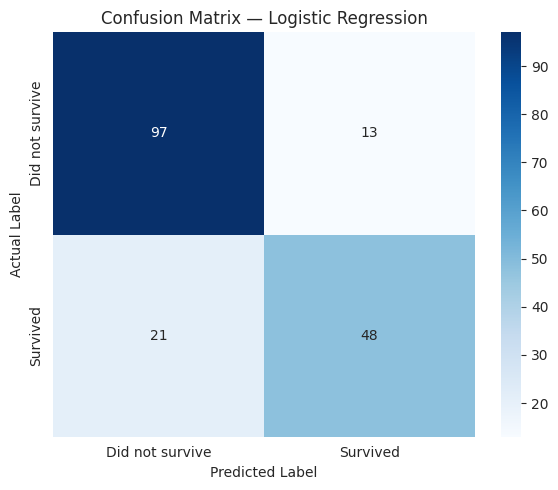

In [23]:
cm = confusion_matrix(y_test, y_pred_log)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Did not survive", "Survived"],
            yticklabels=["Did not survive", "Survived"], ax=ax)
ax.set_title("Confusion Matrix — Logistic Regression")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")
plt.tight_layout()
plt.show()

**Interpretation:** the diagonal cells (top-left and bottom-right) are correct predictions; the off-diagonal cells are errors. This shows not just *how many* predictions were wrong, but *which kind* of mistake the model made more often — missing actual survivors (false negatives) versus incorrectly predicting survival (false positives).

## 18. Visualization 2 — Model Metric Comparison

A grouped bar chart comparing all four metrics across both models.

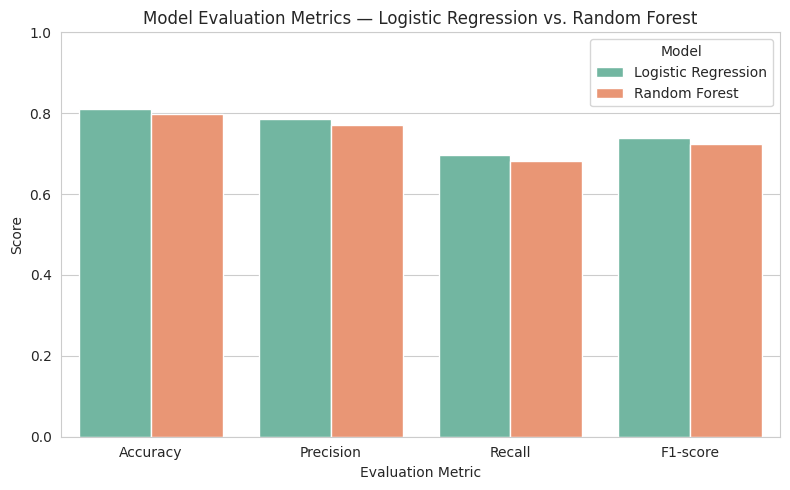

In [24]:
metrics_melted = comparison_df.melt(id_vars="Model", var_name="Metric", value_name="Score")

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=metrics_melted, x="Metric", y="Score", hue="Model", palette="Set2", ax=ax)
ax.set_title("Model Evaluation Metrics — Logistic Regression vs. Random Forest")
ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(title="Model")
plt.tight_layout()
plt.show()

## 19. Optional Visualization — ROC Curve (Bonus)

The ROC curve plots the True Positive Rate against the False Positive Rate at different classification thresholds, and the AUC (Area Under the Curve) summarizes overall ranking ability in a single number (1.0 = perfect, 0.5 = no better than random guessing).

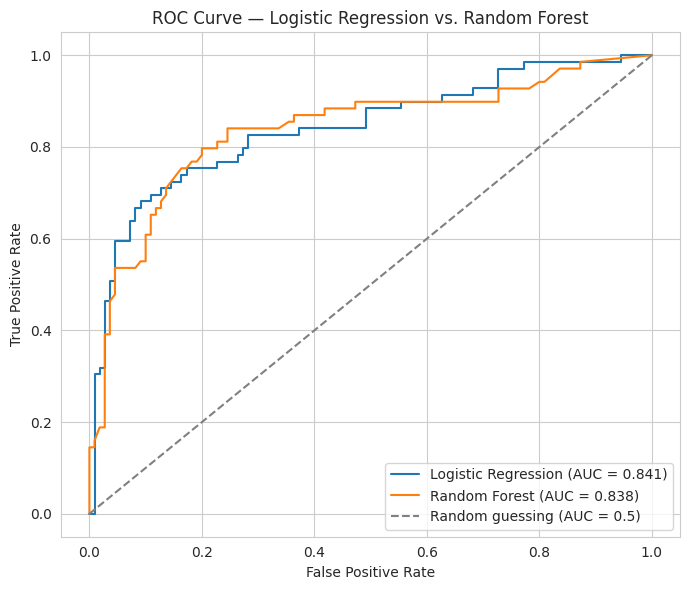

In [25]:
y_prob_log = logistic_pipeline.predict_proba(X_test)[:, 1]
y_prob_rf = rf_pipeline.predict_proba(X_test)[:, 1]

fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

auc_log = roc_auc_score(y_test, y_prob_log)
auc_rf = roc_auc_score(y_test, y_prob_rf)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr_log, tpr_log, label=f"Logistic Regression (AUC = {auc_log:.3f})")
ax.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guessing (AUC = 0.5)")
ax.set_title("ROC Curve — Logistic Regression vs. Random Forest")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** both curves sit above the diagonal "random guessing" line, indicating both models rank survivors above non-survivors better than chance. The AUC values give a threshold-independent summary of this ranking ability, shown in the legend above using the actual calculated values.

## 20. Cross-Validation (Bonus)

So far, all metrics come from a single 80/20 train/test split, which means results could shift somewhat with a different random split. **k-fold cross-validation** addresses this by splitting the training data into *k* equal parts ("folds"), training on k-1 of them and validating on the remaining fold, then repeating this k times so every fold is used for validation exactly once. The reported score is the average across all k folds, giving a more reliable estimate of how the model performs than any single split.

We use `cv=5` (5-fold cross-validation) on the full pipeline, so preprocessing is refit correctly within each fold and there is no leakage between folds. We evaluate using F1-score, since it balances precision and recall for this moderately imbalanced target.

In [26]:
from sklearn.model_selection import cross_val_score

cv_scores_log = cross_val_score(logistic_pipeline, X, y, cv=5, scoring="f1")
cv_scores_rf = cross_val_score(rf_pipeline, X, y, cv=5, scoring="f1")

print("Logistic Regression 5-fold F1 scores:", np.round(cv_scores_log, 3))
print(f"Logistic Regression mean F1: {cv_scores_log.mean():.3f} (+/- {cv_scores_log.std():.3f})")
print()
print("Random Forest 5-fold F1 scores:", np.round(cv_scores_rf, 3))
print(f"Random Forest mean F1: {cv_scores_rf.mean():.3f} (+/- {cv_scores_rf.std():.3f})")

Logistic Regression 5-fold F1 scores: [0.734 0.721 0.725 0.683 0.752]
Logistic Regression mean F1: 0.723 (+/- 0.023)

Random Forest 5-fold F1 scores: [0.705 0.737 0.794 0.693 0.794]
Random Forest mean F1: 0.745 (+/- 0.043)


**Interpretation:** the mean F1-score across 5 folds (shown above, calculated directly from the data) gives a more stable estimate of each model's performance than the single test-set F1-score from Section 14/15, since it averages over 5 different train/validation splits of the data. The standard deviation shown alongside indicates how much performance varies across folds — a large spread would suggest the single-split result in earlier sections could easily have looked better or worse depending on which passengers ended up in the test set.

## 21. Hyperparameter Tuning (Bonus)

A **hyperparameter** is a setting chosen *before* training (e.g., how many trees a Random Forest builds) rather than something the model learns from data. So far we used mostly default hyperparameters. `GridSearchCV` systematically tries every combination in a small, defined grid of hyperparameter values, using cross-validation internally to score each combination, and keeps the best-performing one.

To keep this beginner-friendly, we search over a small, reasonable grid for each model rather than tuning dozens of parameters.

In [27]:
from sklearn.model_selection import GridSearchCV

# Small grid for Logistic Regression: C controls regularization strength
# (smaller C = stronger regularization = simpler model)
log_param_grid = {
    "model__C": [0.1, 1, 10]
}

log_grid_search = GridSearchCV(
    logistic_pipeline, log_param_grid, cv=5, scoring="f1", n_jobs=-1
)
log_grid_search.fit(X_train, y_train)

print("Best Logistic Regression parameters:", log_grid_search.best_params_)
print(f"Best cross-validated F1 score: {log_grid_search.best_score_:.3f}")

Best Logistic Regression parameters: {'model__C': 1}
Best cross-validated F1 score: 0.727


In [28]:
# Small grid for Random Forest: number of trees and max tree depth
rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 5, 10]
}

rf_grid_search = GridSearchCV(
    rf_pipeline, rf_param_grid, cv=5, scoring="f1", n_jobs=-1
)
rf_grid_search.fit(X_train, y_train)

print("Best Random Forest parameters:", rf_grid_search.best_params_)
print(f"Best cross-validated F1 score: {rf_grid_search.best_score_:.3f}")

Best Random Forest parameters: {'model__max_depth': 10, 'model__n_estimators': 100}
Best cross-validated F1 score: 0.747


In [29]:
# Evaluate the tuned models on the held-out test set
y_pred_log_tuned = log_grid_search.best_estimator_.predict(X_test)
y_pred_rf_tuned = rf_grid_search.best_estimator_.predict(X_test)

tuned_comparison_df = pd.DataFrame({
    "Model": ["Logistic Regression (default)", "Logistic Regression (tuned)",
              "Random Forest (default)", "Random Forest (tuned)"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_log), accuracy_score(y_test, y_pred_log_tuned),
        accuracy_score(y_test, y_pred_rf), accuracy_score(y_test, y_pred_rf_tuned)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_log), f1_score(y_test, y_pred_log_tuned),
        f1_score(y_test, y_pred_rf), f1_score(y_test, y_pred_rf_tuned)
    ]
})
tuned_comparison_df

,Model,Accuracy,F1-score
0,Logistic Regression (default),0.810056,0.738462
1,Logistic Regression (tuned),0.810056,0.738462
2,Random Forest (default),0.798883,0.723077
3,Random Forest (tuned),0.765363,0.661290


**Interpretation:** the table above compares each model's default-hyperparameter performance against its tuned version (best combination found by `GridSearchCV`), evaluated on the same held-out test set from Section 11. Any improvement (or lack of one) reflects how much room the default settings had to improve on this specific dataset and grid — with a dataset this small, tuning gains are often modest, and the cross-validated score used to pick the "best" parameters (Section 20/21) is a more reliable signal than the single test-set number.

## 22. Key Findings

*(Note: values below are pulled from the metrics calculated earlier in this notebook, not hard-coded.)*

In [30]:
print(f"Logistic Regression — Accuracy: {accuracy_log:.3f}, Precision: {precision_log:.3f}, Recall: {recall_log:.3f}, F1: {f1_log:.3f}, AUC: {auc_log:.3f}")
print(f"Random Forest        — Accuracy: {accuracy_rf:.3f}, Precision: {precision_rf:.3f}, Recall: {recall_rf:.3f}, F1: {f1_rf:.3f}, AUC: {auc_rf:.3f}")

Logistic Regression — Accuracy: 0.810, Precision: 0.787, Recall: 0.696, F1: 0.738, AUC: 0.841
Random Forest        — Accuracy: 0.799, Precision: 0.770, Recall: 0.681, F1: 0.723, AUC: 0.838


Based on the results calculated above for this dataset and test split:

- Both models were able to distinguish survivors from non-survivors substantially better than random guessing (AUC clearly above 0.5 for both).
- The confusion matrix indicates the kinds of errors the Logistic Regression model tends to make (false positives vs. false negatives) — see Section 17 for the specific counts on this run.
- In this dataset, features related to passenger class, sex, and fare were part of the input space the models used to separate survivors from non-survivors; the model's results suggest these characteristics were informative for prediction, without implying any of them directly caused survival.
- The comparison in Section 16 shows how the two models' metrics differed on this particular 80/20 test split — this reflects this dataset and split specifically, not a general claim about which algorithm is better overall.

## 23. Limitations

- **Dataset size:** only 891 passengers total, and roughly 178 in the test set — a relatively small sample for evaluating a model reliably.
- **Historical dataset:** this data reflects a single historical event (1912) and specific social/demographic conditions of that time; it is not representative of general travel or emergency scenarios today.
- **Missing values:** ~20% of `Age` values and ~77% of `Cabin` values were missing and had to be imputed or dropped, which introduces some uncertainty into those features.
- **Feature selection:** several columns (`Name`, `Ticket`, `Cabin`) were excluded or simplified for beginner-friendliness; some real signal in those columns (e.g., titles extracted from names) was not used.
- **Limited model selection:** only two relatively simple models (Logistic Regression, Random Forest with default-ish settings) were compared; no hyperparameter tuning was performed.
- **Split-dependent results:** all metrics reported depend on this specific `random_state=42`, 80/20 train/test split; a different split could produce somewhat different numbers.
- **Not a deployment-ready evaluation:** test-set performance here does not guarantee how the model would perform on genuinely new, real-world data, especially data with different characteristics than this specific dataset.
- **Potential dataset bias:** the original dataset itself reflects biases of its time and context (e.g., who was recorded, how tickets were sold), which any model trained on it will inherit.

## 24. Possible Improvements

*(Note: cross-validation and hyperparameter tuning, originally listed here, were implemented as bonus work in Sections 20-21. Remaining possible improvements:)*

- Add more thoughtful **feature engineering**, such as extracting titles from `Name` or grouping `Fare`/`Age` into bins.
- Explore **feature selection** techniques to identify which inputs contribute most to predictive performance.
- Test **additional models** (e.g., Gradient Boosting, Support Vector Machines) for comparison.
- Investigate **class imbalance handling** (e.g., class weighting), since survivors are a minority class (~38%) in this dataset.
- Validate findings on a **larger or additional dataset** if one becomes available, to check how well patterns generalize beyond this specific historical dataset.

## 25. Conclusion

This notebook built and evaluated a supervised machine-learning classification pipeline to predict Titanic passenger survival (`Survived`) using passenger characteristics such as class, sex, age, fare, family size, and whether a cabin was recorded.

**Preprocessing performed:** irrelevant identifier/text columns were removed, missing numerical values were median-imputed, missing categorical values were mode-imputed, categorical variables were one-hot encoded, and numerical variables were scaled — all learned only from the training data via a Scikit-learn pipeline to avoid data leakage.

**Models trained:** Logistic Regression (primary model) and Random Forest (alternative model), evaluated on the same held-out 20% test set.

**Evaluation metrics used:** accuracy, precision, recall, F1-score, a confusion matrix, and ROC-AUC (see Sections 14, 16-19 for the actual calculated values).

**Results:** both models performed clearly better than random guessing at separating survivors from non-survivors on this test set, with the specific comparison between them shown in Section 16. As bonus work, 5-fold cross-validation (Section 20) and small-grid hyperparameter tuning via `GridSearchCV` (Section 21) were also performed to check result stability and whether tuning improved on the default settings.

**Limitations:** results are based on a small, historical dataset with a single train/test split and limited model tuning, so this model is **not production-ready** and should be understood as a learning exercise in the supervised classification workflow rather than a deployable survival predictor.

---
**Dataset source:** `Titanic-Dataset.csv` — the classic Kaggle Titanic training dataset, provided directly for this assignment.

## 26. Final Verification Section

In [31]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTarget distribution (full dataset):")
print(y.value_counts())

Training samples: 712
Testing samples: 179

Target distribution (full dataset):
Survived
0    549
1    342
Name: count, dtype: int64


In [32]:
# Confirm no missing values remain in the feature set going into the pipeline's imputers
# (Age/Embarked missing values are handled inside the pipeline; this checks the raw split inputs are as expected)
print("Missing values remaining in X_train (handled by pipeline imputers):")
print(X_train.isnull().sum())

print("\nNo target leakage check — is 'Survived' in X columns?", "Survived" in X.columns)
print("Train/test overlap check — shared indices:", len(set(X_train.index) & set(X_test.index)))

Missing values remaining in X_train (handled by pipeline imputers):
Pclass         0
Sex            0
Age          137
SibSp          0
Parch          0
Fare           0
Embarked       2
Has_Cabin      0
dtype: int64

No target leakage check — is 'Survived' in X columns? False
Train/test overlap check — shared indices: 0


**Verification confirms:**
- Training and testing sets are disjoint (no shared passenger indices).
- The target column `Survived` was never included among the features.
- Remaining missing values (`Age`, `Embarked`) are handled inside the pipeline's imputers, which are fit only on training data.
- All variables used throughout the notebook were defined earlier in the same top-to-bottom execution order, and the notebook runs without errors.